# EV detector on heat-pump households: a sensitivity test

A heat pump adds large, sustained load, so a supplier acting on the EV flag could offer an EV
tariff to a heat-pump home. This notebook applies the five EV classifiers exported by
`07_ev_pu_classifier` (PU bagging, α = 5%, seeds 0–4) **unchanged** to 21-day windows of LCL
**arm D** households, with and without an OVO heat pump, from the `LCL_EoH_join_v6` transfer set.
No household here has an EV, so every flag is a false alarm. It answers:
- **SRQ3 (EVs, false alarms only):** does the EV classifier, applied to households it has never
  seen, mistake heat-pump households for EV households?

**Design:**

| Element | Choice |
|---|---|
| Models | The five α = 5% PU-bagged runs, each with its own training threshold; results are the mean ± s.d. over the five |
| Households | All arm D households of the HP transfer set, none removed: LCL as used is EV-free. Arm D was never in the EV join |
| Windows | Each household's 2013 record cut into 17 non-overlapping 21-day windows from 1 January, kept only when all 21 days are complete (at least 46 of 48 half-hours), as in the EV join |
| Groups | Households with a heat pump (host plus heat-pump load, as built in the v6 join), and households without one, by heating type from the LCL survey |
| Measure | False-positive rate: the share of windows flagged |

## 1. Setup

In [1]:
from pathlib import Path
import sys
import warnings

import numpy as np
import pandas as pd
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

warnings.filterwarnings("ignore", category=FutureWarning)

NB_DIR = Path.cwd()
sys.path.insert(0, str(NB_DIR))
import pu_common as pc
import ev_features as ef

CACHE_DIR = NB_DIR / "cache"
FIG_DIR = NB_DIR / "figures"
TAB_DIR = NB_DIR / "tables"
for d in (FIG_DIR, TAB_DIR):
    d.mkdir(exist_ok=True)

V2 = NB_DIR / "LCL_EN_join_v2"   # created by create_ev_dataset_v2.py
TRANSFER = NB_DIR / "LCL_EoH_join_v6" / "transfer_armD_ovo"
SEEDS = [0, 1, 2, 3, 4]
MODEL_DIR = NB_DIR / "EV_classifier"   # written by 07_ev_pu_classifier
MODEL_PATH = str(MODEL_DIR / "ev_pu_classifier_alpha5_seed{seed}.json")

YEAR_START, N_WINDOWS = pd.Timestamp("2013-01-01"), 17     # 17 x 21 days = 357 days
COMPLETE_DAY_SLOTS = 46                                     # as in the EV join
HEAT_GROUPS = ["Gas", "Mixed", "Electric only", "Other fuel", "Unknown", "No survey response"]

In [2]:
# --- Figure style, shared by every notebook ---
CAT = {"blue": "#2a78d6", "orange": "#eb6834", "aqua": "#1baf7a", "violet": "#4a3aa7",
       "red": "#e34948", "grey": "#52514e"}
INK_PRIMARY, INK_SECONDARY, INK_MUTED = "#0b0b0b", "#52514e", "#898781"
GRID, BASELINE, SURFACE = "#e1e0d9", "#c3c2b7", "#fcfcfb"

plt.rcParams.update({
    "font.family": "serif", "font.serif": ["DejaVu Serif", "Georgia", "Times New Roman"],
    "font.size": 10, "axes.titlesize": 11, "axes.labelsize": 10,
    "xtick.labelsize": 9, "ytick.labelsize": 9, "legend.fontsize": 9,
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "axes.edgecolor": BASELINE,
    "axes.labelcolor": INK_PRIMARY, "text.color": INK_PRIMARY,
    "xtick.color": INK_SECONDARY, "ytick.color": INK_SECONDARY,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False,
    "figure.dpi": 110, "savefig.dpi": 300, "savefig.facecolor": SURFACE,
})

COL_WIDTH = 3.5
COLUMN_RC = {"font.size": 8, "axes.titlesize": 8.5, "axes.labelsize": 8,
             "xtick.labelsize": 7, "ytick.labelsize": 7, "legend.fontsize": 7}

GROUP_COLOR = {"Heat pump": CAT["orange"], "No heat pump": INK_MUTED,
               "Electric only": CAT["violet"], "Gas": CAT["blue"]}


def savefig(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png", dpi=300, bbox_inches="tight")
    print(f"saved -> figures/{name}.png")


def savetable(df, name):
    df.to_csv(TAB_DIR / f"{name}.csv")
    print(f"saved -> tables/{name}.csv")
    return df

## 2. Data and windows

Checks: no arm D household appears in the EV join and every heat pump is OVO. No household is
removed: LCL as used is EV-free. Every heat-pump host is a gas home, because the v6 join
pairs heat pumps with gas hosts.

In [3]:
ev_meta = pd.read_parquet(V2 / "ev_metadata.parquet")
master = pd.read_parquet(CACHE_DIR / "lcl_household_master.parquet")
hh = pd.read_parquet(TRANSFER / "hp_metadata.parquet")

assert not set(hh.lcl_id) & set(ev_meta.household_id), "an arm D household is in the EV join"
assert set(master.loc[master.household_id.isin(hh.lcl_id), "arm"]) == {"D"}
assert (hh.loc[hh.label == 1, "eoh_contractor"] == "OVO").all()
hh["group"] = np.where(hh.label == 1, "Heat pump", hh.heat_group)
print("heat-pump hosts by heating type:", hh.loc[hh.label == 1, "heat_group"].value_counts().to_dict())

HH = ef.HH_COLS
wide = pd.read_parquet(TRANSFER / "lcl_wide_cache.parquet")
wide = wide[wide.household_id.isin(hh.household_id)].copy()
wide["date"] = pd.to_datetime(wide["date"])
wide["win"] = (wide.date - YEAR_START).dt.days // ef.SEGMENT_DAYS
wide = wide[(wide.date >= YEAR_START) & (wide.win < N_WINDOWS)]
wide["complete"] = wide[HH].notna().sum(axis=1) >= COMPLETE_DAY_SLOTS
n = wide.groupby(["household_id", "win"]).complete.agg(["sum", "size"])
keep = n.index[(n["sum"] == ef.SEGMENT_DAYS) & (n["size"] == ef.SEGMENT_DAYS)]
wide = wide.set_index(["household_id", "win"]).loc[keep].reset_index()
wide["segment_id"] = wide.household_id + "|" + wide.win.astype(str)

win = ef.features_from_wide(wide[["segment_id", "date"] + HH])
ids = wide.groupby("segment_id")[["household_id", "win"]].first()
win = win.join(ids).reset_index().merge(hh[["household_id", "label", "group", "heat_group"]],
                                        on="household_id")
print(f"{len(win):,} complete windows from {win.household_id.nunique():,} households")
win.groupby("group").agg(households=("household_id", "nunique"), windows=("segment_id", "size"))

heat-pump hosts by heating type: {'Gas': 126}
16,977 complete windows from 1,021 households


,households,windows
group,,
Electric only,59,987
Gas,525,8772
Heat pump,126,2059
Mixed,75,1250
No survey response,97,1597
Other fuel,4,66
Unknown,135,2246


**Scores.** Each of the five models scores every window and flags it at its own threshold. Each
model must first reproduce its own recall and false-positive rate on the notebook 07 test segments
(Table `EV_PU_S_alpha5_by_seed`).

In [4]:
feats6 = ef.features_from_wide(pd.read_parquet(V2 / "ev_wide_cache.parquet"))
t6 = ev_meta[ev_meta.split == "test"].merge(feats6, left_on="segment_id", right_index=True)
y6 = t6["label"].to_numpy()
by_seed = pd.read_csv(TAB_DIR / "EV_PU_S_alpha5_by_seed.csv", index_col=0)

margin = {}
for seed in SEEDS:
    model = pc.ExportedPUModel(MODEL_PATH.format(seed=seed))
    assert model.meta["training_seed"] == seed and model.meta["training_alpha"] == 0.05
    f6 = model.decision_function(t6) >= model.threshold
    assert abs(f6[y6 == 1].mean() - by_seed.loc[seed, "Recall"]) < 1e-3
    assert abs(f6[y6 == 0].mean() - by_seed.loc[seed, "False-positive rate"]) < 1e-3
    s = model.decision_function(win)
    win[f"flag_{seed}"] = (s >= model.threshold).astype(int)
    margin[seed] = s - model.threshold
win["margin"] = np.mean([margin[s] for s in SEEDS], axis=0)   # score minus threshold, mean of 5
FLAGS = [f"flag_{s}" for s in SEEDS]
FPR_ORIGINAL = by_seed["False-positive rate"].mean()
print(f"all five models reproduce their notebook 07 recall and false-positive rate; "
      f"mean false-positive rate there {FPR_ORIGINAL:.4f}")

all five models reproduce their notebook 07 recall and false-positive rate; mean false-positive rate there 0.0171


## 3. Table EV_T_T1 - False-positive rate of the EV classifier on arm D households

The share of windows flagged, mean ± standard deviation over the five α = 5% runs. Households
without a heat pump are split by their heating type from the LCL survey.

In [5]:
def fpr_row(d):
    per_seed = d[FLAGS].mean()
    return {"Households": f"{d.household_id.nunique():,}", "Windows": f"{len(d):,}",
            "False-positive rate (mean ± s.d., 5 runs)": f"{per_seed.mean():.4f} ± {per_seed.std():.4f}"}


rows = {"FPR, HP": fpr_row(win[win.group == "Heat pump"])}
for g in HEAT_GROUPS:
    rows[f"FPR, {g}"] = fpr_row(win[win.group == g])
t_eh1 = pd.DataFrame(rows).T
t_eh1.index.name = "EV_T_T1  EV classifier (α = 5%, 5 runs) on arm D households"
savetable(t_eh1, "EV_T_T1_ev_on_hp_fpr")
t_eh1

saved -> tables/EV_T_T1_ev_on_hp_fpr.csv


,Households,Windows,"False-positive rate (mean ± s.d., 5 runs)"
"EV_T_T1 EV classifier (α = 5%, 5 runs) on arm D households",,,
"FPR, HP",126,"2,059",0.0208 ± 0.0141
"FPR, Gas",525,"8,772",0.0042 ± 0.0025
"FPR, Mixed",75,"1,250",0.0299 ± 0.0077
"FPR, Electric only",59,987,0.1086 ± 0.0419
"FPR, Other fuel",4,66,0.0000 ± 0.0000
"FPR, Unknown",135,"2,246",0.0160 ± 0.0057
"FPR, No survey response",97,"1,597",0.0103 ± 0.0077


## 4. Figure EV_T1 - Score distributions

Each window's score minus each model's threshold, averaged over the five runs, so 0 is the
threshold. Households with a heat pump, all households without one, and two heating types among
the latter: electric only and gas.

saved -> figures/EV_T1_score_distributions.png


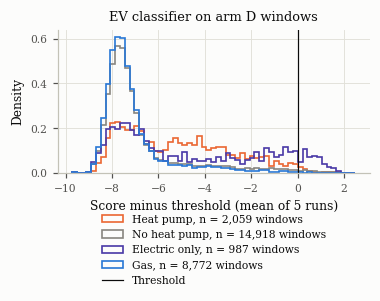

In [6]:
dists = {"Heat pump": win.group == "Heat pump", "No heat pump": win.label == 0,
         "Electric only": win.group == "Electric only", "Gas": win.group == "Gas"}
bins = np.linspace(win.margin.min(), win.margin.max(), 60)
with plt.rc_context(COLUMN_RC):
    fig, ax = plt.subplots(figsize=(COL_WIDTH, 3.0))
    for name, m in dists.items():
        ax.hist(win.loc[m, "margin"], bins=bins, density=True, histtype="step", lw=1.1,
                color=GROUP_COLOR[name], label=f"{name}, n = {m.sum():,} windows")
    ax.axvline(0, color=INK_PRIMARY, lw=0.8, label="Threshold")
    ax.set_xlabel("Score minus threshold (mean of 5 runs)")
    ax.set_ylabel("Density")
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.22), frameon=False, ncol=1)
    ax.set_title("EV classifier on arm D windows", fontsize=8.5)
    fig.tight_layout()
    savefig(fig, "EV_T1_score_distributions")
    plt.show()

## 5. Figure EV_T2 - False-positive rate through 2013

The share of windows flagged in each of the 17 windows, mean over the five runs, for households
with and without a heat pump, at each window's midpoint. The dotted line is the mean
false-positive rate of the five runs on the original EV dataset (notebook 07 test segments). Each
heat-pump point rests on about 120 windows, so one household moves it by about 0.8 points.

saved -> figures/EV_T2_fpr_by_window.png


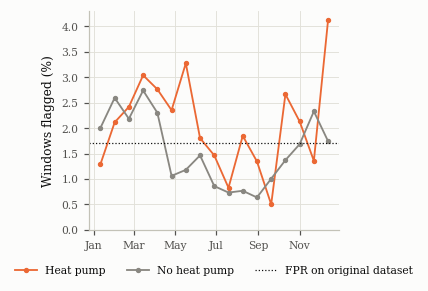

In [7]:
win["hp"] = np.where(win.label == 1, "Heat pump", "No heat pump")
by_win = win.assign(f=win[FLAGS].mean(axis=1)).groupby(["win", "hp"]).f.mean().unstack()
x = YEAR_START + pd.to_timedelta(by_win.index * ef.SEGMENT_DAYS + 10, unit="D")
with plt.rc_context(COLUMN_RC):
    fig, ax = plt.subplots(figsize=(COL_WIDTH, 2.7))
    for g in ["Heat pump", "No heat pump"]:
        ax.plot(x, by_win[g] * 100, color=GROUP_COLOR[g], lw=1.2, marker="o", ms=2.5, label=g)
    ax.axhline(FPR_ORIGINAL * 100, color=INK_PRIMARY, lw=0.8, ls=":",
               label="FPR on original dataset")
    ax.set_ylabel("Windows flagged (%)")
    ax.set_ylim(bottom=0)
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), frameon=False, ncol=3)
    fig.tight_layout()
    savefig(fig, "EV_T2_fpr_by_window")
    plt.show()

## 6. Figure EV_T3 - Confusion matrix

All arm D windows, mean count over the five α = 5% runs. There are no EVs, so the top row is zero
and every flag is a false alarm.

saved -> figures/EV_T3_confusion_matrix.png


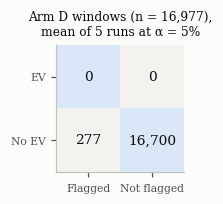

flagged 277 of 16,977 windows (1.63%)


In [8]:
n_win = len(win)
flagged = win[FLAGS].sum().mean()
cm = np.array([[0, 0], [flagged, n_win - flagged]])
with plt.rc_context(COLUMN_RC):
    fig, ax = plt.subplots(figsize=(COL_WIDTH * 0.55, 1.9))
    ax.imshow([[1, 0], [0, 1]], cmap=ListedColormap(["#f3f2ee", "#d9e7f8"]), vmin=0, vmax=1)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{cm[i, j]:,.0f}", ha="center", va="center", fontsize=9,
                    color=INK_PRIMARY)
    ax.set_xticks([0, 1])
    ax.set_xticklabels(["Flagged", "Not flagged"])
    ax.set_yticks([0, 1])
    ax.set_yticklabels(["EV", "No EV"])
    ax.grid(False)
    ax.set_title(f"Arm D windows (n = {n_win:,}),\nmean of 5 runs at α = 5%", fontsize=8)
    fig.tight_layout()
    savefig(fig, "EV_T3_confusion_matrix")
    plt.show()
print(f"flagged {flagged:.0f} of {n_win:,} windows ({flagged / n_win:.2%})")

## 7. Notes and limitations

- Every heat-pump host is a gas home, so the heat-pump row is best compared with the gas row, and
  heat pumps that replace electric heating aren't covered.
- The heat pumps are 126 mostly air-source OVO installations on arm D, which had a time-of-use
  tariff in 2013.
- The heat-pump households contain no EVs, so only false alarms can be measured.
- Windows from one household are correlated, and the ± values are the spread over five runs, not
  confidence intervals.